In [1]:
import sys
sys.path.append('../../src/gerry09/')

from communicate import CableRobot, MotorState, ControllerState
import numpy as np
import matplotlib.pyplot as plt
import time

In [5]:
# Function for recording data
def collect_data(duration=5):
    """Collects log data from the cable robot.  Returns tuple of Nx4 arrays for lengths and vels"""
    with CableRobot(print_raw=True, write_timeout=None, initial_msg='d10,1', port='/dev/tty.usbmodem100994303') as robot:
        tstart = time.time()
        while True:
            robot.update()
            time.sleep(0.01)
            if (time.time() - tstart > duration):
                break
        robot.send('d10,100')
    motor_ls = np.array([[m.length for m in datum['motors']] for datum in robot.all_data])
    motor_ldots = np.array([[m.lengthdot for m in datum['motors']] for datum in robot.all_data])
    xy = np.array([[dat['controller'].cur_x, dat['controller'].cur_y] for dat in robot.all_data])
    xy_com = np.array([[dat['controller'].set_x, dat['controller'].set_y] for dat in robot.all_data])
    return motor_ls, motor_ldots, xy, xy_com
def collect_points(N):
    motor_ls = []
    motor_ldots = []
    xy = []
    xy_commanded = []
    for i in range(N):
        input(f'Press enter to record point {i}')
        a, b, c, d = collect_data(0.5)
        motor_ls.append(a[-1])
        motor_ldots.append(b[-1])
        xy.append(c[-1])
        xy_commanded.append(d[-1])
        print(f'point {i}: ', motor_ls[-1], motor_ldots[-1], xy[-1], xy_commanded[-1])
    return np.array(motor_ls), np.array(motor_ldots), np.array(xy), np.array(xy_commanded)


In [6]:
# Collect 4 corners, in order: BR, TR, TL, BL
# xy4 = np.array([[92, 24],
#                 [92, 65],
#                 [24, 65],
#                 [24, 24]])
# Y has 
# For each of the 4 corners, put the brush in "painting" position and just barely touch the mullions with the brush.
USE_CORNERS = True
if True:
    # Collect some data
    ls4, ldots4, xy4, xy_com4 = collect_points(4)
    print(ls4)
    print(ldots4)
    print(xy4)
    # Save/Load data (in case of ipynb failure)
    np.savez('/tmp/4pts_data.npz', ls4=ls4, ldots4=ldots4, est4=xy4, com4=xy_com4)
    np.savez(f'/tmp/4pts_data_{time.time()}.npz', ls4=ls4, ldots4=ldots4, est4=xy4, com4=xy_com4)
else:
    with np.load('/tmp/4pts_data.npz') as f:
        ls4 = f['ls4']
        ldots4 = f['ldots4']
        xy4 = f['est4']
        xy_com4 = f['com4']

# print(ls4)
# print(ldots4)
# print(xy4)
# xy4 = xy_com4

point 0:  [-0.7767 -0.4281  0.7372  0.7837] [0.8985 0.6606 0.4125 0.4847] [2.4872 0.8007] [2.4813 0.801 ]
point 1:  [ 0.2184 -1.4182  0.3215  1.2467] [0.3993 0.9649 0.6313 0.4237] [2.5168 1.8035] [2.512 1.8  ]
point 2:  [ 1.3155  0.2563 -1.4007  0.1306] [0.2469 0.5471 1.0708 0.4311] [0.8388 1.7759] [0.84 1.77]
point 3:  [ 0.8086  0.7178 -0.4904 -0.7901] [0.5492 0.4272 0.6155 0.9398] [0.8471 0.8236] [0.85  0.825]
[[-0.7767 -0.4281  0.7372  0.7837]
 [ 0.2184 -1.4182  0.3215  1.2467]
 [ 1.3155  0.2563 -1.4007  0.1306]
 [ 0.8086  0.7178 -0.4904 -0.7901]]
[[0.8985 0.6606 0.4125 0.4847]
 [0.3993 0.9649 0.6313 0.4237]
 [0.2469 0.5471 1.0708 0.4311]
 [0.5492 0.4272 0.6155 0.9398]]
[[2.4872 0.8007]
 [2.5168 1.8035]
 [0.8388 1.7759]
 [0.8471 0.8236]]


In [7]:
PANE = 'TEST_1'

In [21]:
# 4 Corner Constants
# First define X1, X2, Y1, Y2 are the bounds of the pane relative to the bottom-left pulley.
inch2m = lambda x: x * 0.0254
if PANE == 'TEST_1':
    X1 = inch2m(24)
    X2 = inch2m(92)
    Y1 = inch2m(24)
    Y2 = inch2m(65)
else:
    raise RuntimeError(f'Unknown pane: {PANE}')

BRUSH_R = 0
baseTbrush = np.array([0, 0])       # brush in the base coordinate frame
baseTcdprrest = -np.array([0.187, 0.122]) / 2  # cdpr has a carriagewidth/2 offset we need to correct for
XY4_ORIGIN = np.array([[X2 - BRUSH_R, Y1 + BRUSH_R],
                [X2 - BRUSH_R, Y2 - BRUSH_R],
                [X1 + BRUSH_R, Y2 - BRUSH_R],
                [X1 + BRUSH_R, Y1 + BRUSH_R]]) - baseTbrush
print('Corner Locs: (using bottom-left coordinate system)')
print(XY4_ORIGIN)

print('Expected Corner Locs: (using carriage-center coordinate system)')
XY4 = XY4_ORIGIN - baseTcdprrest
print(XY4)
print('Actual corner locs: (using carriage-center coordinate system)')
print(xy4)

Corner Locs: (using bottom-left coordinate system)
[[2.3368 0.6096]
 [2.3368 1.651 ]
 [0.6096 1.651 ]
 [0.6096 0.6096]]
Expected Corner Locs: (using carriage-center coordinate system)
[[2.4303 0.6706]
 [2.4303 1.712 ]
 [0.7031 1.712 ]
 [0.7031 0.6706]]
Actual corner locs: (using carriage-center coordinate system)
[[2.4872 0.8007]
 [2.5168 1.8035]
 [0.8388 1.7759]
 [0.8471 0.8236]]


In [32]:
# Compute an xy homography correction using the 4 corners
def compute_H(act, est):
    # act is 2x4, est is 2x4
    A = np.zeros((8, 9))
    for i in range(4):
        A[2*i, 0:3] = act[:, i]
        A[2*i, 6:9] = -est[0, i] * act[:, i]
        A[2*i+1, 3:6] = act[:, i]
        A[2*i+1, 6:9] = -est[1, i] * act[:, i]
    _, _, V = np.linalg.svd(A)
    H = V[-1, :].reshape(3, 3)
    return H

def make_homogeneous(x):
    return np.vstack((x, np.ones(x.shape[1])))

In [33]:
H = compute_H(make_homogeneous(XY4_ORIGIN.T), make_homogeneous(xy4.T))
print(H)

# Sanity check
def apply_H(good):
    pred = H @ make_homogeneous(good.T)
    pred /= pred[-1, :]
    return pred[:-1, :].T
print('applying homography to expected corners: ', apply_H(XY4))
print('actual measure corners:                  ', xy4)

[[ 0.52379893 -0.01518768  0.1953646 ]
 [-0.02167417  0.52350557  0.18547655]
 [-0.01718951 -0.01243733  0.61470084]]
applying homography to expected corners:  [[2.58272722 0.85702756]
 [2.61469714 1.86545103]
 [0.92486805 1.83457469]
 [0.93132523 0.87720462]]
actual measure corners:                   [[2.4872 0.8007]
 [2.5168 1.8035]
 [0.8388 1.7759]
 [0.8471 0.8236]]


In [34]:
# Here are the limits we should use post-homography
print('The following should be typed into gcode webpage:')
print('H:')
print(H.tolist())

The following should be typed into gcode webpage:
H:
[[0.5237989279341662, -0.01518768038512393, 0.1953645980517818], [-0.021674168983994806, 0.5235055693660097, 0.18547654537906982], [-0.017189510876584643, -0.01243733068295738, 0.6147008420075405]]


In [35]:
xy4

array([[2.4872, 0.8007],
       [2.5168, 1.8035],
       [0.8388, 1.7759],
       [0.8471, 0.8236]])

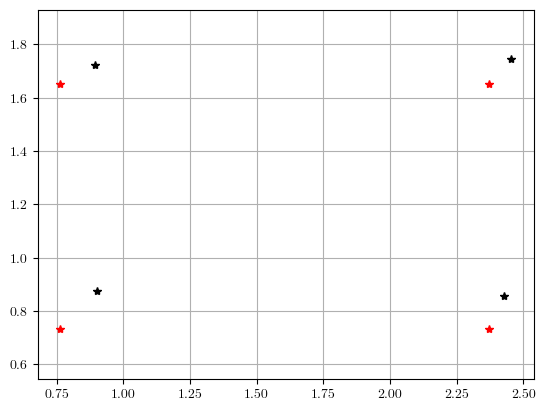

In [36]:
plt.plot(*XY60.T, 'r*')
plt.plot(*XY60_cdpr_coords.T, 'k*')
plt.axis('equal');

In [37]:
# Do a test position.
xy = inch2m(55), inch2m(55)
apply_H(np.array(xy)[None, :])

array([[1.58010696, 1.54633915]])